In [3]:

# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")


In [4]:

train = pd.read_csv('/content/dataset_C_training.csv')
test = pd.read_csv('/content/dataset_C_testing.csv')

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

display(train.head())
display(test.head())


Training shape: (4756, 31)
Testing shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


In [5]:

# Column names
print("Column names:")
print(train.columns.tolist())

# Data types
print("\nData types:")
print(train.dtypes)

# Dataset information
print("\nDataset information:")
train.info()

# Statistical summary
print("\nStatistical summary:")
display(train.describe(include='all').T)


Column names:
['respondent_id', 'covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'employment_sector', 'number_chronic_med_conditions', 'covid_vaccine']

Data types:
respondent_id                      int64
covid_concern                    float64
covid_knowledge                  float64
behavioral_antiviral_meds        float64
behavioral_avoidance             float64
behavioral_face_mask             float64
behavioral_wash_hands            float64
behavioral_large_gatherings      float6

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0


In [6]:

missing = train.isnull().sum()

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': (missing / len(train)) * 100
})

missing_table = missing_table[
    missing_table['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

display(missing_table)


,Missing Values,Missing Percentage
employment_sector,2330,48.990749
health_insurance,1908,40.117746
income_poverty,748,15.727502
rent_or_own,329,6.917578
employment_status,238,5.004205
marital_status,231,4.857023
education,228,4.793944
child_under_6_months,135,2.838520
health_worker,132,2.775442
opinion_covid_sick_from_vacc,90,1.892347


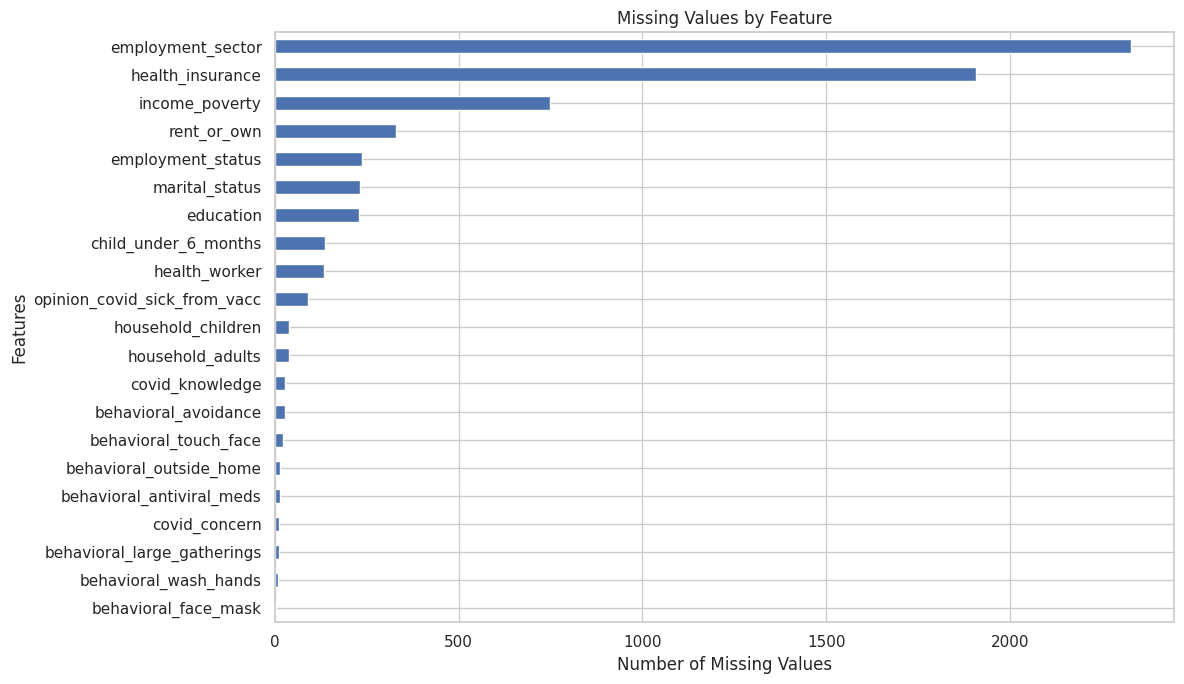

In [7]:

plt.figure(figsize=(12, 7))

missing_values = train.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values()

missing_values.plot(kind='barh')

plt.title('Missing Values by Feature')
plt.xlabel('Number of Missing Values')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


covid_vaccine
0    3202
1    1554
Name: count, dtype: int64

Percentage distribution:
covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


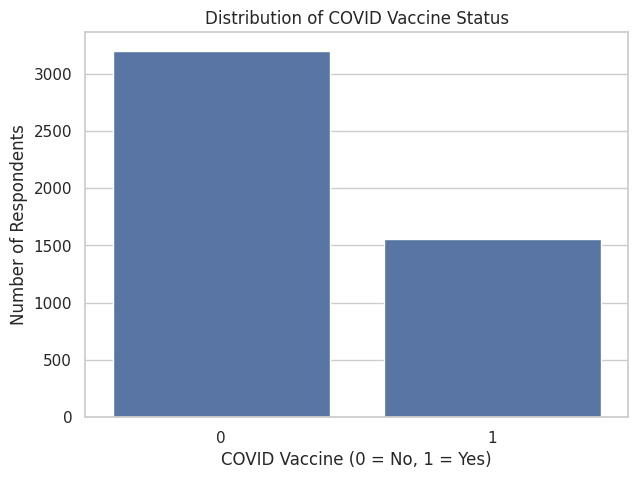

In [8]:

print(train['covid_vaccine'].value_counts())

print("\nPercentage distribution:")
print(train['covid_vaccine'].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x='covid_vaccine'
)

plt.title('Distribution of COVID Vaccine Status')
plt.xlabel('COVID Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Number of Respondents')

plt.show()


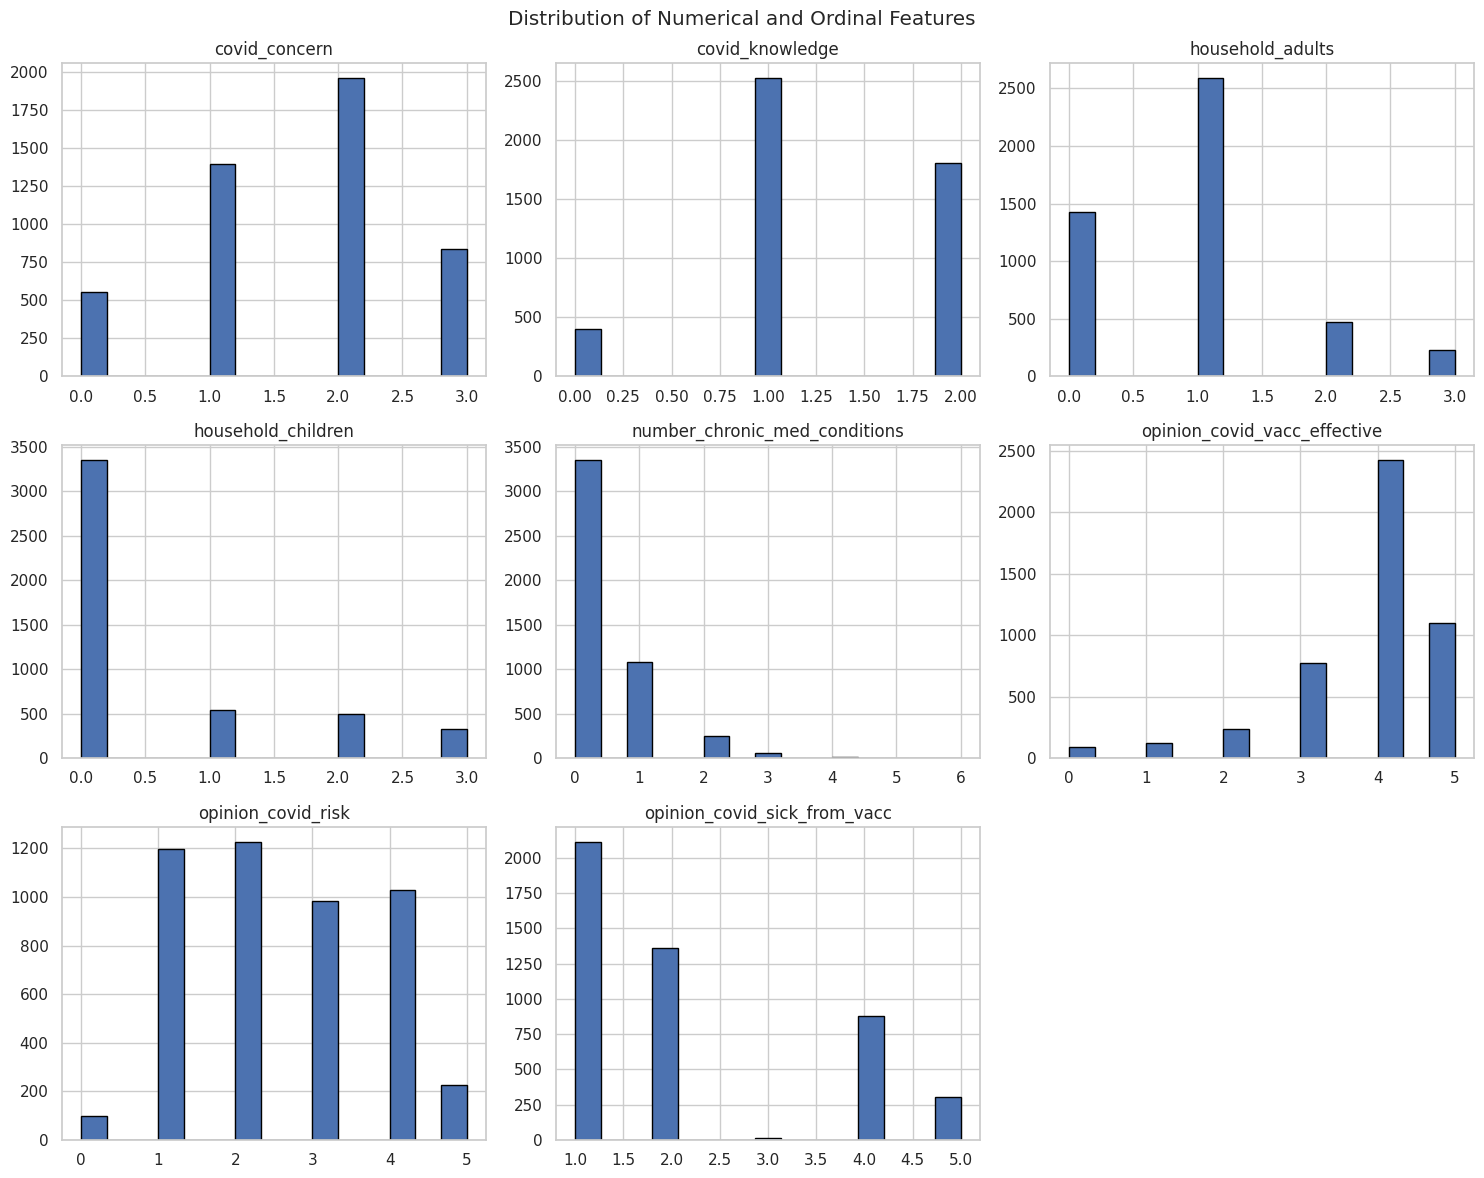

In [9]:

numeric_columns = [
    'covid_concern',
    'covid_knowledge',
    'household_adults',
    'household_children',
    'number_chronic_med_conditions',
    'opinion_covid_vacc_effective',
    'opinion_covid_risk',
    'opinion_covid_sick_from_vacc'
]

train[numeric_columns].hist(
    figsize=(15, 12),
    bins=15,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical and Ordinal Features')
plt.tight_layout()
plt.show()


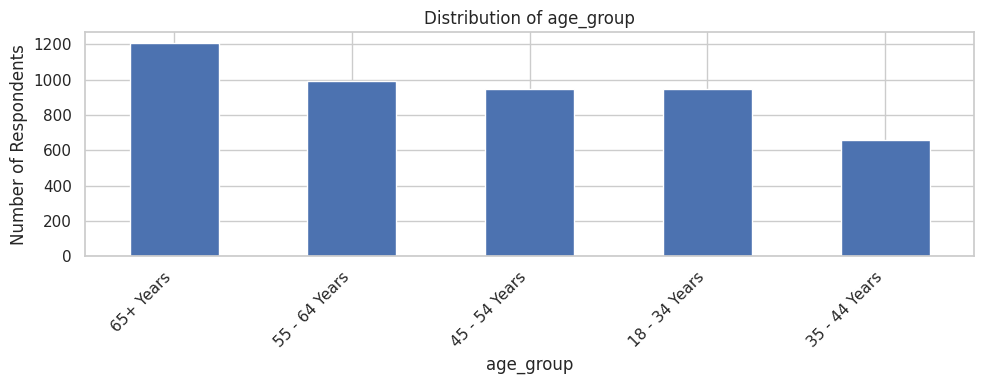

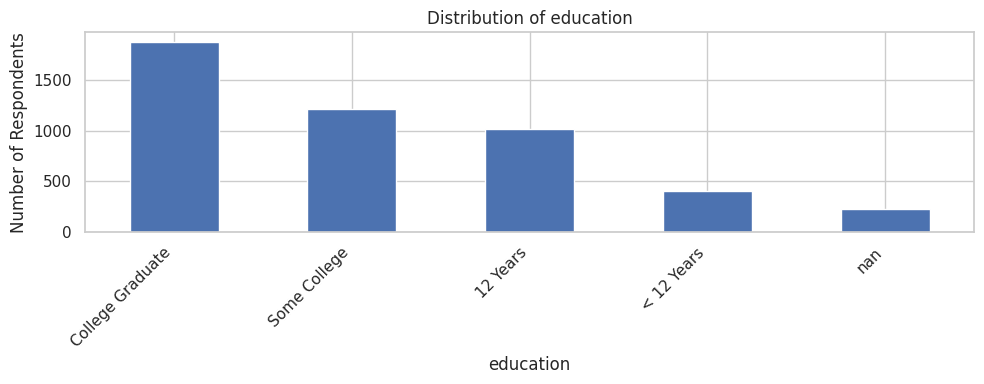

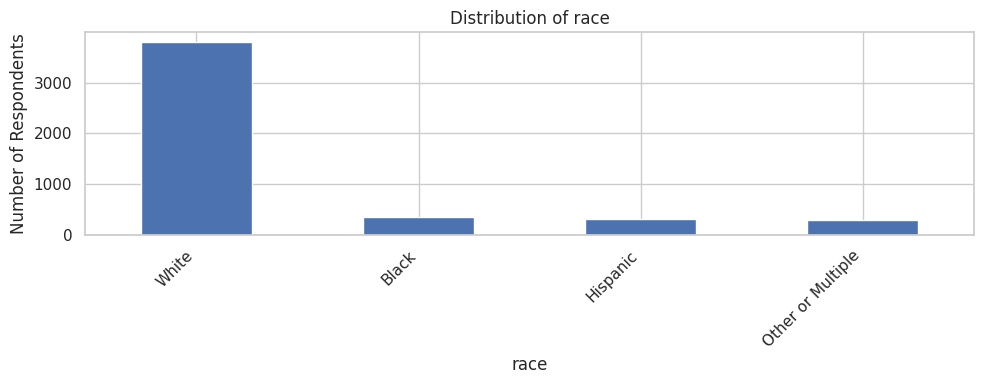

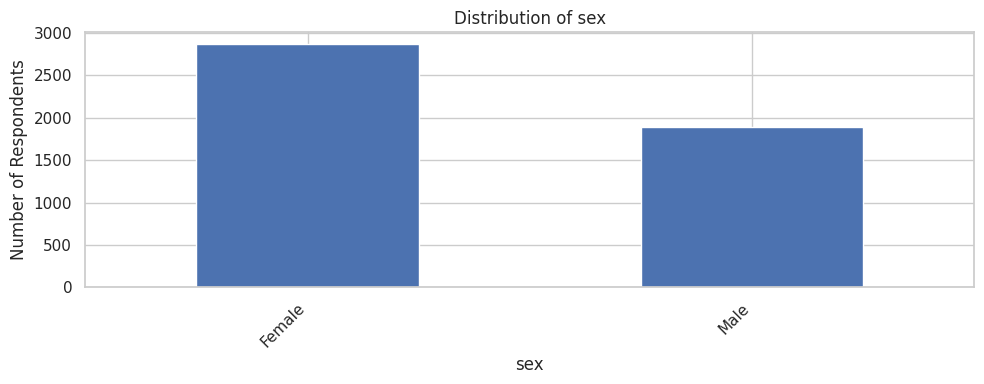

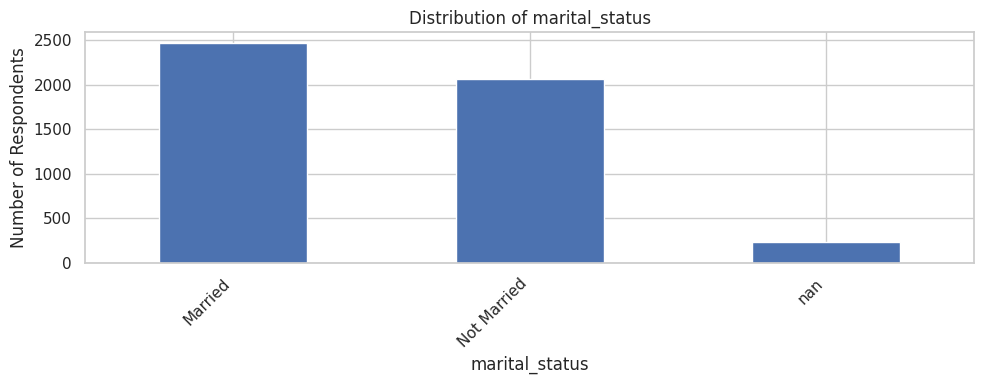

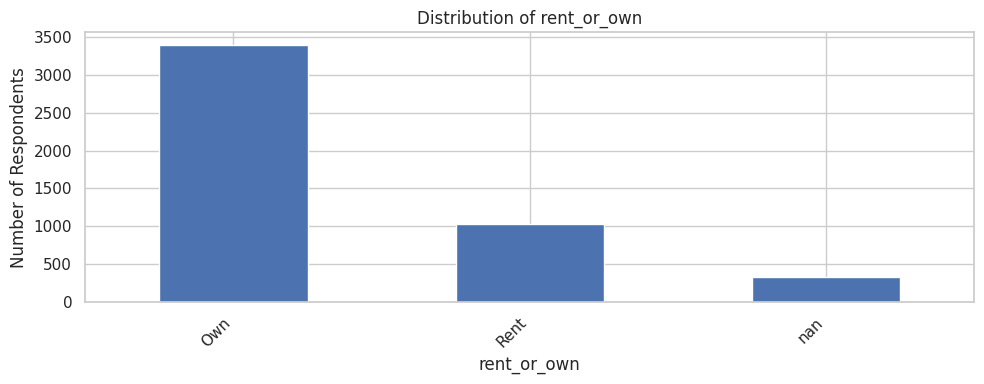

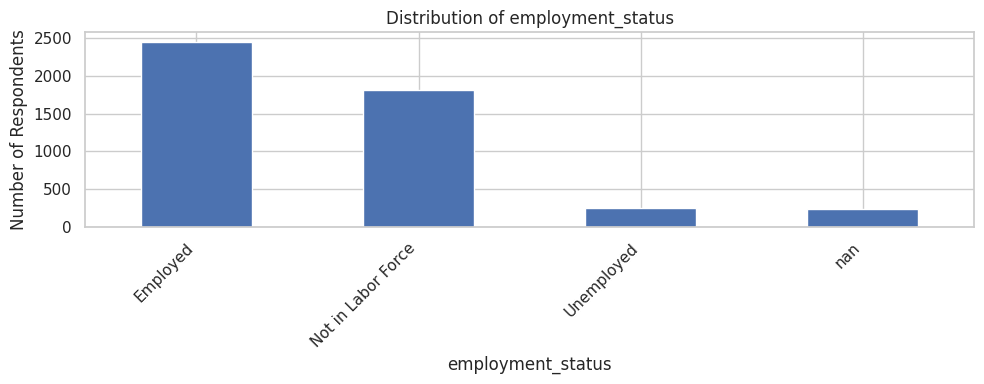

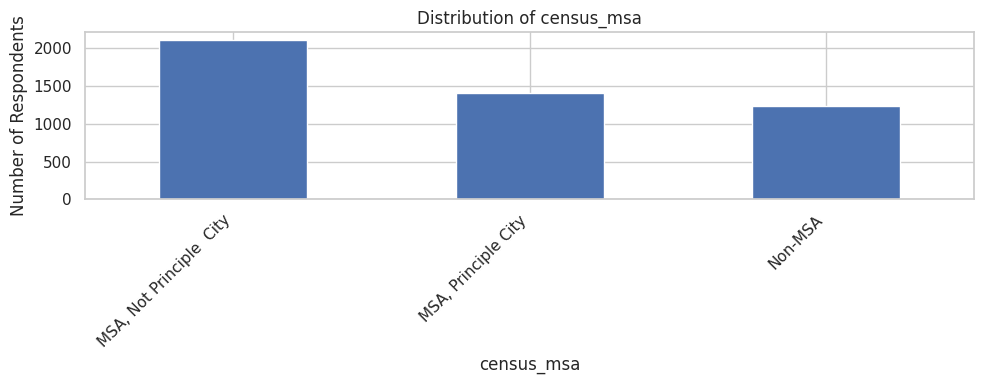

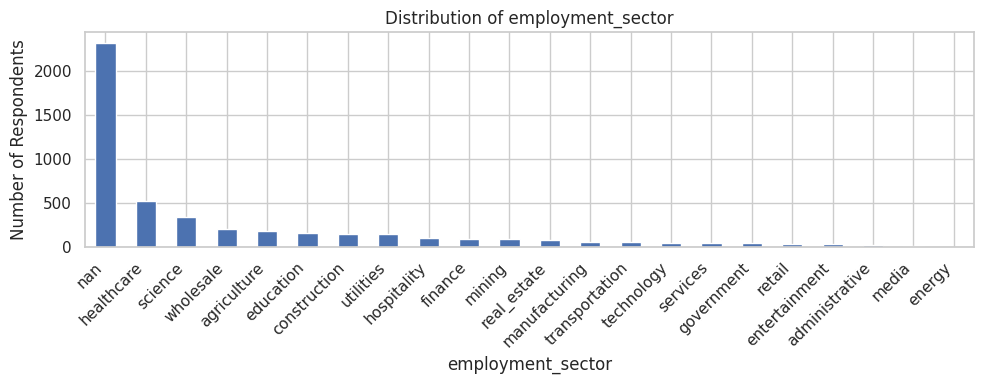

In [10]:

categorical_columns = [
    'age_group',
    'education',
    'race',
    'sex',
    'marital_status',
    'rent_or_own',
    'employment_status',
    'census_msa',
    'employment_sector'
]

for col in categorical_columns:

    plt.figure(figsize=(10, 4))

    train[col].value_counts(
        dropna=False
    ).plot(kind='bar')

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of Respondents')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


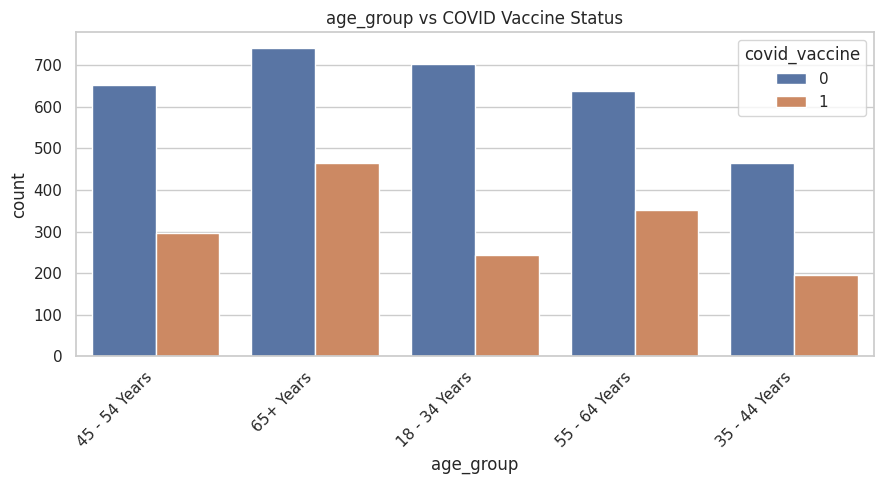

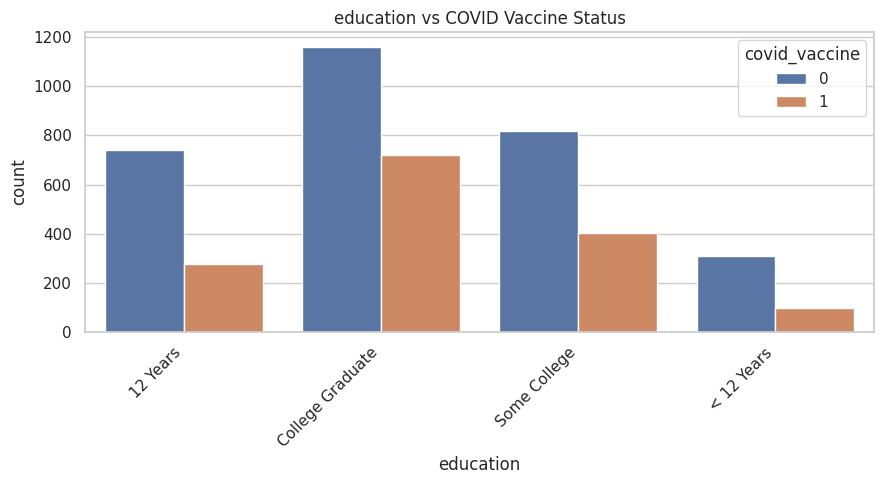

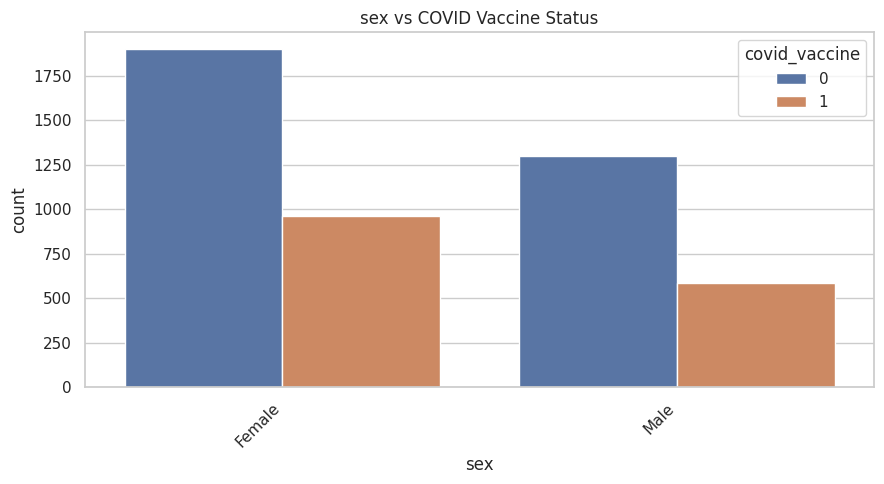

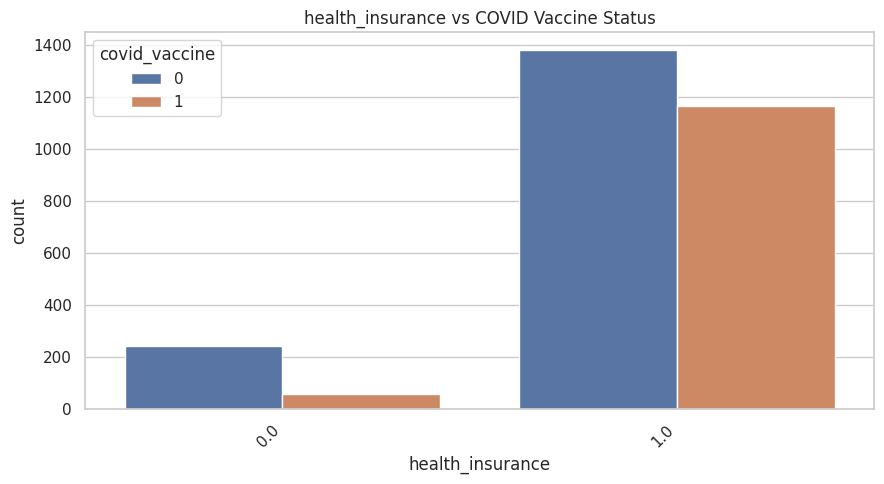

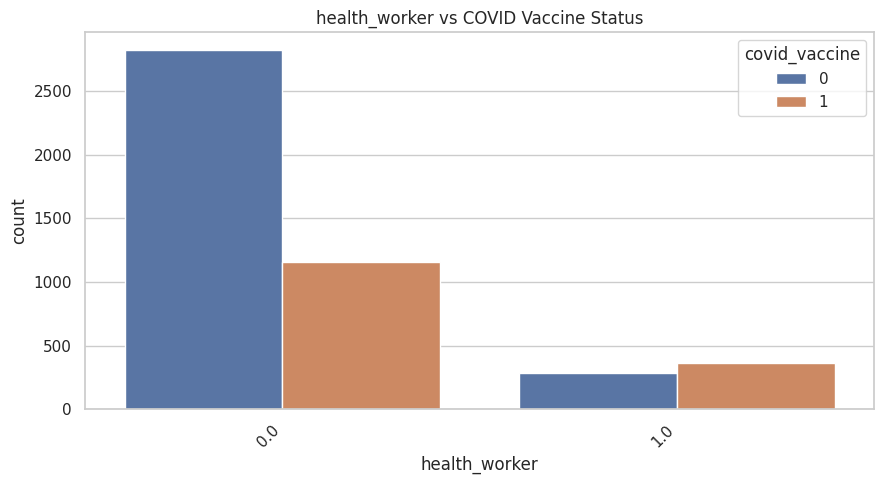

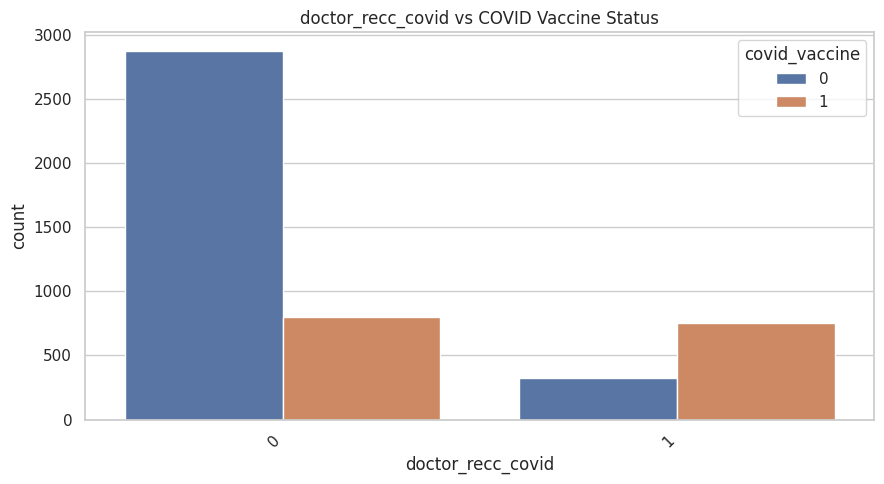

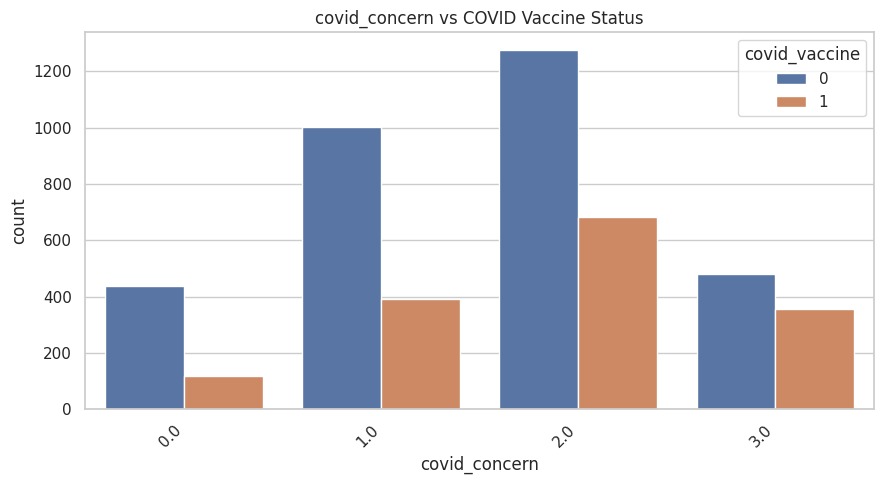

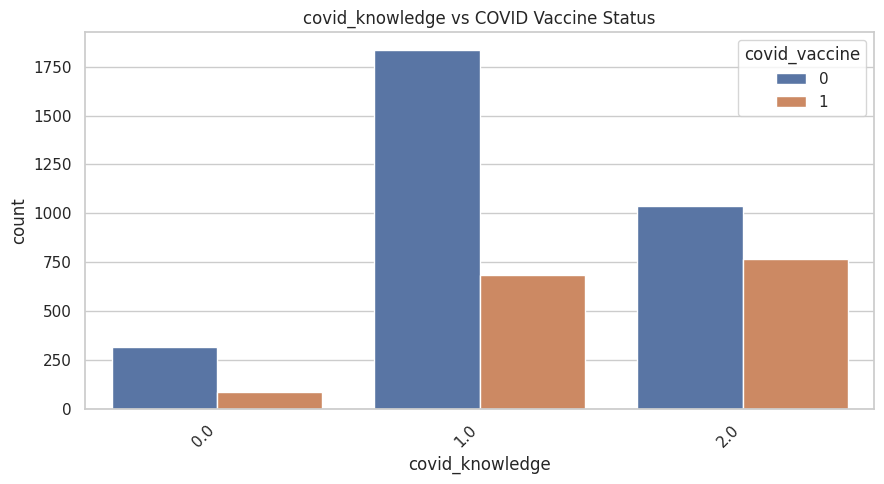

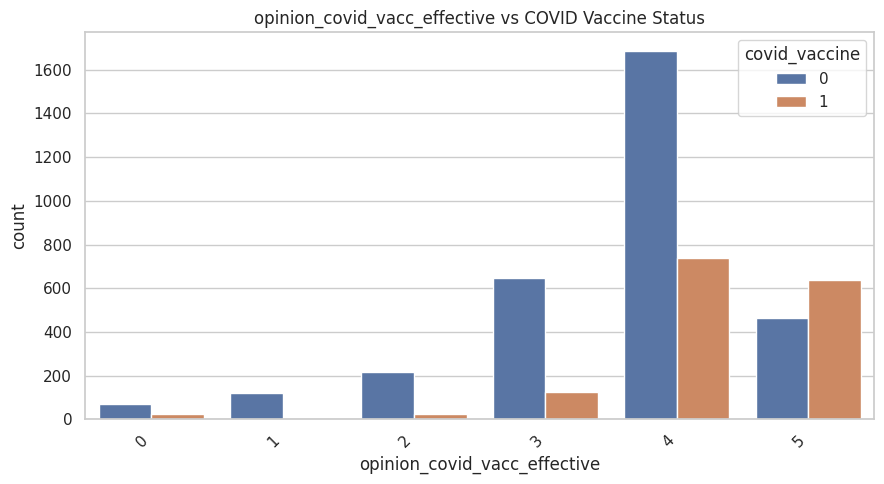

In [11]:

features_to_compare = [
    'age_group',
    'education',
    'sex',
    'health_insurance',
    'health_worker',
    'doctor_recc_covid',
    'covid_concern',
    'covid_knowledge',
    'opinion_covid_vacc_effective'
]

for col in features_to_compare:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=train,
        x=col,
        hue='covid_vaccine'
    )

    plt.title(f'{col} vs COVID Vaccine Status')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


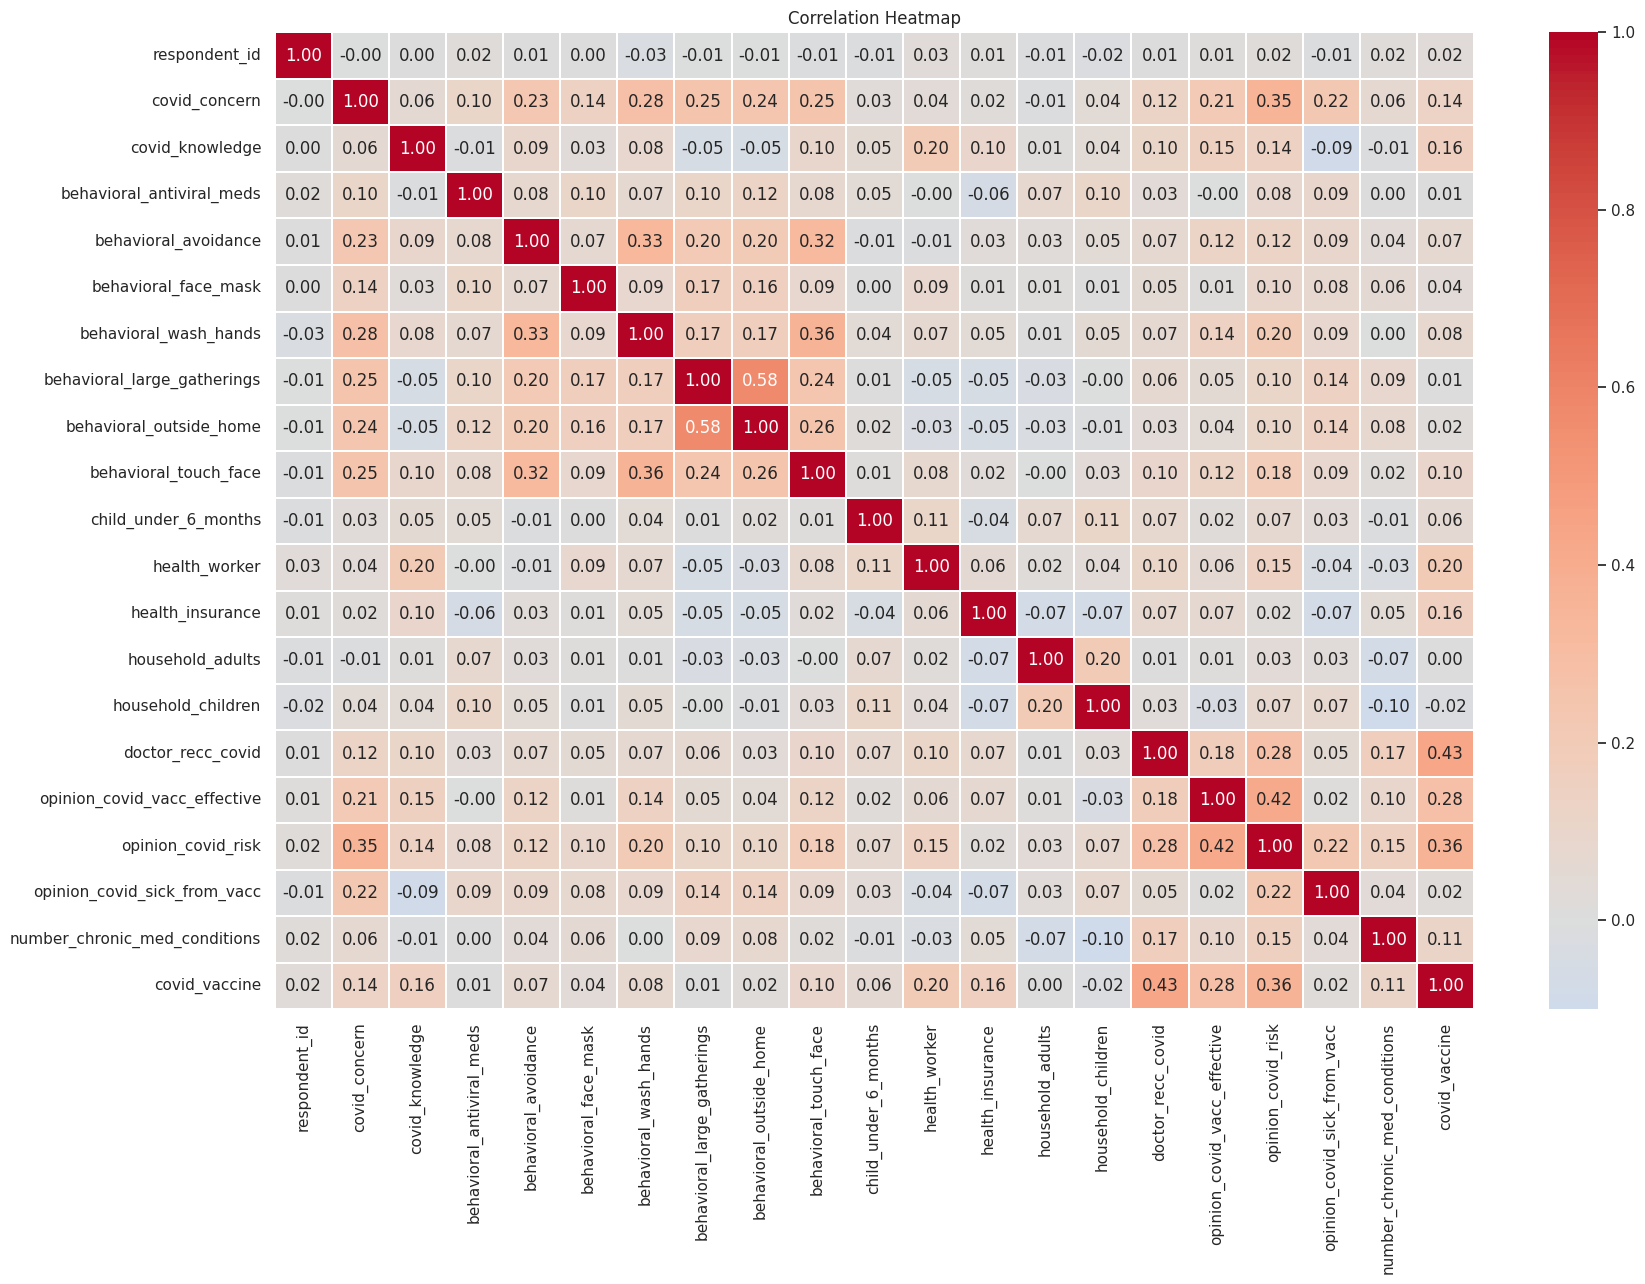

In [12]:

correlation = train.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(18, 13))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.3
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


In [13]:

X = train.drop(
    columns=['covid_vaccine', 'respondent_id']
)

y = train['covid_vaccine']

# Keep testing IDs separately
test_ids = test['respondent_id']

X_test = test.drop(
    columns=['respondent_id']
)

print("Training features:", X.shape)
print("Target:", y.shape)
print("Testing features:", X_test.shape)


Training features: (4756, 29)
Target: (4756,)
Testing features: (4749, 29)


In [14]:

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


Numerical features: ['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']

Categorical features: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


In [15]:

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


In [16]:

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Validation records:", X_val.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))


Training records: 3804
Validation records: 952

Training target distribution:
covid_vaccine
0    0.673239
1    0.326761
Name: proportion, dtype: float64

Validation target distribution:
covid_vaccine
0    0.673319
1    0.326681
Name: proportion, dtype: float64


In [17]:

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        random_state=42
    )
}

print("Five machine learning models created.")


Five machine learning models created.


In [18]:

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Validation predictions
    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(
        y_val, predictions, zero_division=0
    )
    recall = recall_score(
        y_val, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val, predictions, zero_division=0
    )
    auc = roc_auc_score(y_val, probabilities)
    loss = log_loss(y_val, probabilities)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC AUC': auc,
        'Log Loss': loss
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='ROC AUC',
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Log Loss
0,Logistic Regression,0.7700,0.6243,0.7428,0.6784,0.8282,0.5083
2,Random Forest,0.7773,0.7281,0.5080,0.5985,0.8178,0.4834
3,Extra Trees,0.7721,0.7260,0.4855,0.5819,0.8120,0.4887
4,Hist Gradient Boosting,0.7815,0.6988,0.5820,0.6351,0.8066,0.5140
1,Decision Tree,0.6628,0.4828,0.4502,0.4659,0.6081,12.1534


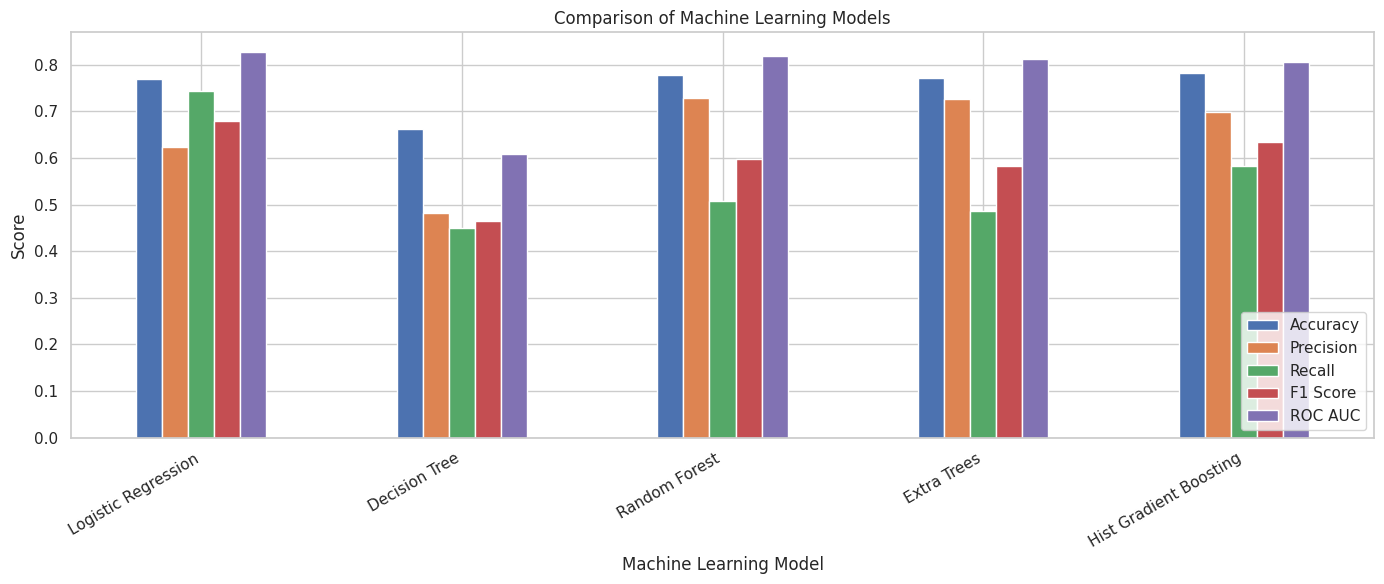

In [19]:

metrics_to_plot = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC AUC'
]

results_df.set_index('Model')[metrics_to_plot].plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.xlabel('Machine Learning Model')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


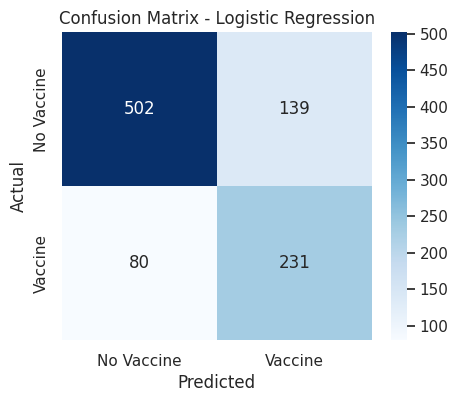

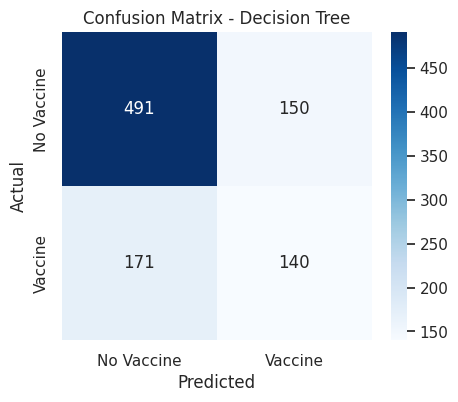

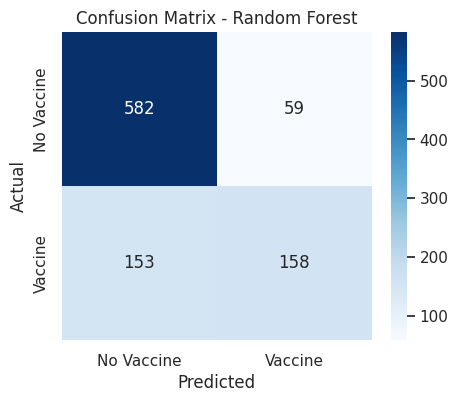

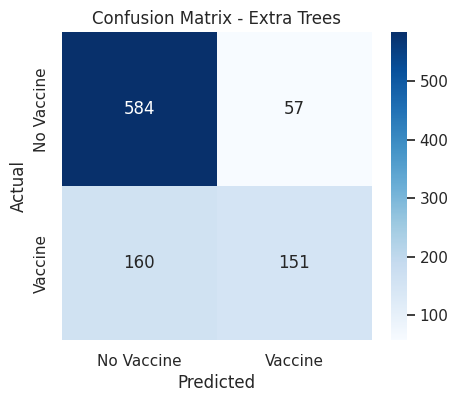

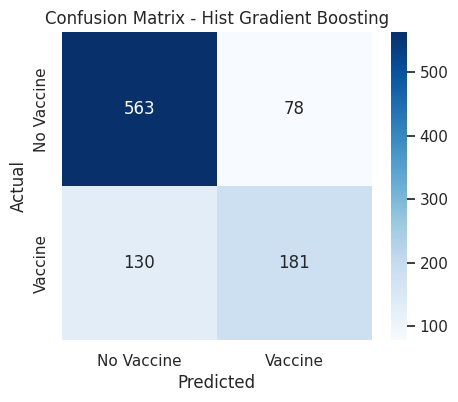

In [20]:

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_val)

    cm = confusion_matrix(y_val, predictions)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Vaccine', 'Vaccine'],
        yticklabels=['No Vaccine', 'Vaccine']
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()


In [21]:

from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2']
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation ROC AUC:")
print(random_search.best_score_)

best_rf = random_search.best_estimator_


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 15}

Best cross-validation ROC AUC:
0.8342418851712026


In [22]:

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_rf,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

print("Cross-validation scores:", cv_scores)
print("Mean ROC AUC:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())


Cross-validation scores: [0.81260611 0.81642978 0.85401763 0.82059488 0.8441674 ]
Mean ROC AUC: 0.8295631615889493
Standard deviation: 0.016442398150192102


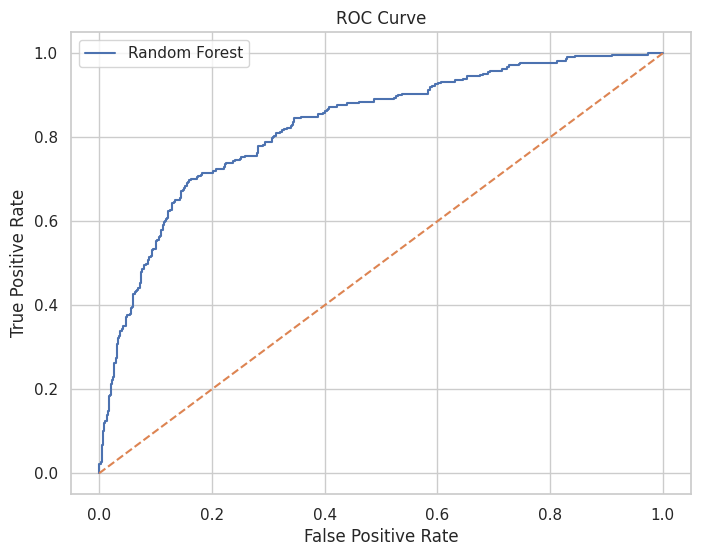

In [23]:

from sklearn.metrics import roc_curve

val_probabilities = best_rf.predict_proba(X_val)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_val,
    val_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label='Random Forest')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


In [24]:

# Replace these with the confirmed assignment assumptions
VACCINE_COST = 1500
HOSPITALISATION_COST = None

# Example only: do not run until the costs
# and their corresponding error types are confirmed.

def calculate_total_cost(
    y_true,
    y_pred,
    false_positive_cost,
    false_negative_cost
):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    total_cost = (
        fp * false_positive_cost +
        fn * false_negative_cost
    )

    return {
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Total Cost': total_cost
    }


In [25]:

!pip install shap -q

import shap


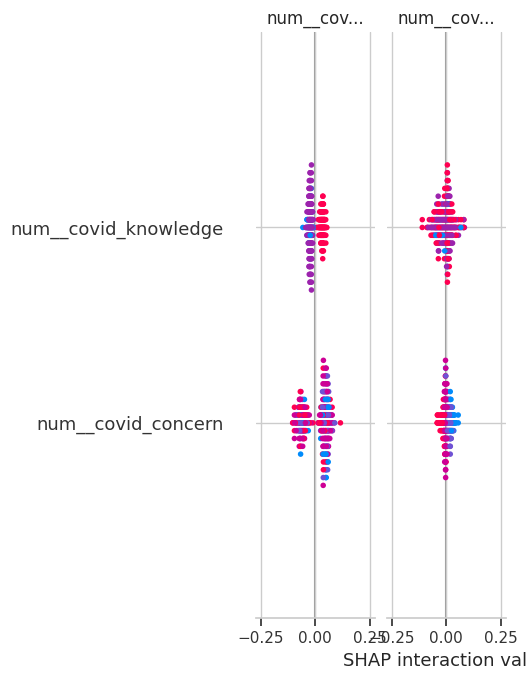

In [26]:

# Transform validation data using fitted preprocessing
X_val_transformed = best_rf.named_steps[
    'preprocessor'
].transform(X_val)

# Get transformed feature names
feature_names = best_rf.named_steps[
    'preprocessor'
].get_feature_names_out()

# Explain the fitted random forest
explainer = shap.TreeExplainer(
    best_rf.named_steps['model']
)

# Use a sample to reduce computation
sample_data = X_val_transformed[:300]

shap_values = explainer.shap_values(sample_data)

# SHAP summary plot
if isinstance(shap_values, list):
    shap.summary_plot(
        shap_values[1],
        sample_data,
        feature_names=feature_names
    )
else:
    shap.summary_plot(
        shap_values,
        sample_data,
        feature_names=feature_names
    )


In [27]:

# Evaluate tuned Random Forest
tuned_predictions = best_rf.predict(X_val)
tuned_probabilities = best_rf.predict_proba(X_val)[:, 1]

tuned_results = {
    'Model': 'Tuned Random Forest',
    'Accuracy': accuracy_score(y_val, tuned_predictions),
    'Precision': precision_score(
        y_val, tuned_predictions, zero_division=0
    ),
    'Recall': recall_score(
        y_val, tuned_predictions, zero_division=0
    ),
    'F1 Score': f1_score(
        y_val, tuned_predictions, zero_division=0
    ),
    'ROC AUC': roc_auc_score(
        y_val, tuned_probabilities
    ),
    'Log Loss': log_loss(
        y_val, tuned_probabilities
    )
}

final_results = pd.concat([
    results_df,
    pd.DataFrame([tuned_results])
], ignore_index=True)

display(
    final_results.sort_values(
        by='ROC AUC',
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Log Loss
0,Logistic Regression,0.7700,0.6243,0.7428,0.6784,0.8282,0.5083
5,Tuned Random Forest,0.7941,0.7018,0.6431,0.6711,0.8266,0.4909
2,Random Forest,0.7773,0.7281,0.5080,0.5985,0.8178,0.4834
3,Extra Trees,0.7721,0.7260,0.4855,0.5819,0.8120,0.4887
4,Hist Gradient Boosting,0.7815,0.6988,0.5820,0.6351,0.8066,0.5140
1,Decision Tree,0.6628,0.4828,0.4502,0.4659,0.6081,12.1534


In [28]:

from sklearn.base import clone

# Select the best five configurations based on validation ROC AUC
top_models = final_results.sort_values(
    by='ROC AUC',
    ascending=False
).head(5)['Model'].tolist()

print("Selected models:")
print(top_models)

# Add tuned Random Forest to available models
all_models = dict(models)
all_models['Tuned Random Forest'] = best_rf.named_steps['model']

final_predictions = {}

for name in top_models:

    final_pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', clone(all_models[name]))
    ])

    # Train using complete labelled dataset
    final_pipeline.fit(X, y)

    # Predict testing data
    predictions = final_pipeline.predict(X_test)

    probabilities = final_pipeline.predict_proba(X_test)[:, 1]

    final_predictions[name] = {
        'model': final_pipeline,
        'predictions': predictions,
        'probabilities': probabilities
    }

print("Testing predictions completed.")


Selected models:
['Logistic Regression', 'Tuned Random Forest', 'Random Forest', 'Extra Trees', 'Hist Gradient Boosting']
Testing predictions completed.


In [29]:

import os

os.makedirs('final_submissions', exist_ok=True)

for i, (name, output) in enumerate(
    final_predictions.items(), start=1
):

    submission = pd.DataFrame({
        'respondent_id': test_ids,
        'covid_vaccine': output['predictions']
    })

    filename = f'final_submissions/model_{i}.csv'

    submission.to_csv(
        filename,
        index=False
    )

    print("Saved:", filename)

print("All five prediction files generated.")


Saved: final_submissions/model_1.csv
Saved: final_submissions/model_2.csv
Saved: final_submissions/model_3.csv
Saved: final_submissions/model_4.csv
Saved: final_submissions/model_5.csv
All five prediction files generated.


In [32]:
import os
import pandas as pd

# List the files in final_submissions
submission_dir = 'final_submissions'
files = sorted(os.listdir(submission_dir))
print(f"Generated files in '{submission_dir}':", files)

# Display the first few rows of each file
for filename in files:
    if filename.endswith('.csv'):
        filepath = os.path.join(submission_dir, filename)
        df = pd.read_csv(filepath)
        print(f"\n--- First 5 rows of {filename} (Shape: {df.shape}) ---")
        display(df.head())

Generated files in 'final_submissions': ['model_1.csv', 'model_2.csv', 'model_3.csv', 'model_4.csv', 'model_5.csv']

--- First 5 rows of model_1.csv (Shape: (4749, 2)) ---


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



--- First 5 rows of model_2.csv (Shape: (4749, 2)) ---


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



--- First 5 rows of model_3.csv (Shape: (4749, 2)) ---


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



--- First 5 rows of model_4.csv (Shape: (4749, 2)) ---


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0



--- First 5 rows of model_5.csv (Shape: (4749, 2)) ---


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0


In [33]:
from google.colab import files
import os

submission_dir = 'final_submissions'
files_to_download = sorted([os.path.join(submission_dir, f) for f in os.listdir(submission_dir) if f.endswith('.csv')])

for filepath in files_to_download:
    print(f"Triggering download for: {filepath}")
    files.download(filepath)

Triggering download for: final_submissions/model_1.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggering download for: final_submissions/model_2.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

Triggering download for: final_submissions/model_5.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>